# Grocery Price Elasticity and Discount Optimization

I wanted to see how well price elasticity can actually be recovered from sales data when a store changes prices *because of* how sales are going, and whether those estimates are good enough to set prices with.

The data is simulated: 12 grocery products in 3 categories over 130 weeks. Simulating it means I know each product's true elasticity, so I can check my estimates against the truth instead of just trusting the regression output.

**Plan**
1. Look at the data
2. Show why price is endogenous here
3. Compare a naive regression with one that has controls
4. Check confidence interval coverage and repeat across many simulated datasets
5. Use the estimates to find profit-maximising prices and test how fragile they are

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import elasticity_utils as eu

pd.set_option("display.width", 170)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": .3})

df  = pd.read_csv("data/weekly_sales.csv", parse_dates=["week_start"])
cat = pd.read_csv("data/product_catalog_true_params.csv")
print(df.shape)
print(df.head(4).to_string(index=False))

(1560, 15)
 week week_start   sku  product_name category  price  list_price  cost  competitor_price  discount_pct  holiday_week  on_promo  units  revenue  gross_profit
    0 2021-01-04 SKU01 Whole Milk 2L    Dairy   3.02         3.2   2.3              3.20          5.56             0         0    773  2335.97        558.07
    1 2021-01-11 SKU01 Whole Milk 2L    Dairy   2.56         3.2   2.3              3.21         19.91             0         1    963  2468.11        253.21
    2 2021-01-18 SKU01 Whole Milk 2L    Dairy   2.83         3.2   2.3              3.30         11.44             0         0    696  1972.52        371.72
    3 2021-01-25 SKU01 Whole Milk 2L    Dairy   2.74         3.2   2.3              3.34         14.32             0         0    788  2160.48        348.08


## 1. A first look

In [2]:
print(df[["price", "discount_pct", "units", "revenue", "gross_profit"]].describe().round(2).to_string())
print()
print(df.groupby("category")[["discount_pct", "units", "gross_profit"]].mean().round(1).to_string())
print("\nMissing values:", int(df.isna().sum().sum()))

         price  discount_pct    units  revenue  gross_profit
count  1560.00       1560.00  1560.00  1560.00       1560.00
mean      5.17         10.58   525.80  2462.91        802.64
std       1.81          6.48   253.96   866.72        303.81
min       2.24          0.00   165.00   836.24        -93.33
25%       3.82          5.74   346.00  1880.76        609.90
50%       4.57         10.33   453.00  2293.64        761.85
75%       6.44         14.80   624.25  2888.09        951.47
max       9.90         36.49  1918.00  6868.29       2063.16

           discount_pct  units  gross_profit
category                                    
Beverages          11.0  473.7         928.3
Dairy               9.9  596.9         581.8
Snacks             10.8  506.8         897.8

Missing values: 0


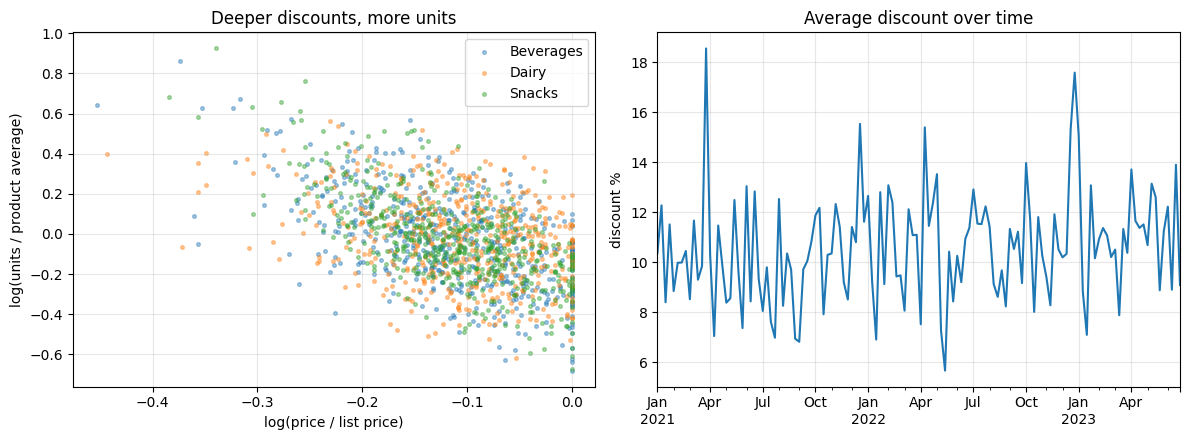

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for cat_name, d in df.groupby("category"):
    ax[0].scatter(np.log(d.price / d.list_price), np.log(d.units / d.groupby("sku").units.transform("mean")), s=7, alpha=.4, label=cat_name)
ax[0].set(xlabel="log(price / list price)", ylabel="log(units / product average)", title="Deeper discounts, more units")
ax[0].legend()
df.groupby("week_start").discount_pct.mean().plot(ax=ax[1])
ax[1].set(title="Average discount over time", ylabel="discount %", xlabel="")
plt.tight_layout(); plt.show()

## 2. Why a plain regression will be off

In this store, discounts follow weak weeks. Demand shocks also carry over from one week to the next. So a low price this week is partly a signal of a bad shock this week, and the regression mixes the two up. The effect is to make demand look less price-sensitive than it is.

I can check both pieces because I know the true elasticity. I take out the price effect, the controls, and seasonality, and what is left is the demand shock.

In [4]:
df = df.sort_values(["sku", "week"]).reset_index(drop=True)
parts = []
for sku, d in df.groupby("sku", sort=False):
    e = cat.loc[cat.sku == sku, "true_elasticity"].iloc[0]
    y = np.log(d.units.values) - e * np.log(d.price.values)
    w = d.week.values
    X = np.column_stack([np.ones(len(d)), np.log(d.competitor_price.values), d.holiday_week.values,
                         np.sin(2*np.pi*w/52), np.cos(2*np.pi*w/52)])
    parts.append(pd.Series(eu.ols(y, X)["resid"], index=d.index))
df["shock"] = pd.concat(parts)
df["shock_prev"] = df.groupby("sku").shock.shift(1)
d = df.dropna(subset=["shock_prev"])
print("corr(discount this week, shock last week):", round(np.corrcoef(d.discount_pct, d.shock_prev)[0, 1], 3))
print("corr(shock this week, shock last week)   :", round(np.corrcoef(d.shock, d.shock_prev)[0, 1], 3))

corr(discount this week, shock last week): -0.221
corr(shock this week, shock last week)   : 0.617


A weak week is followed by a bigger discount (negative correlation), and weak weeks tend to repeat (positive correlation), so price ends up correlated with this week's error term.

## 3. Naive vs controlled regression

For each product I fit a log-log model, so the price coefficient is the elasticity. Standard errors are Newey-West because the residuals are autocorrelated.

- **Naive:** `log(units) ~ log(price)`
- **Controlled:** also includes competitor price, a holiday flag and yearly seasonality (sin and cos terms)

In [5]:
res = eu.compare(df, cat)
print(res[["product_name", "category", "true_elasticity", "elasticity_naive", "elasticity_ctrl", "bias_naive", "bias_ctrl"]].round(2).to_string(index=False))
print()
print("mean absolute bias | naive:", round(res.bias_naive.abs().mean(), 3), " controlled:", round(res.bias_ctrl.abs().mean(), 3))
print("mean signed bias   | naive:", round(res.bias_naive.mean(), 3), " controlled:", round(res.bias_ctrl.mean(), 3))

        product_name  category  true_elasticity  elasticity_naive  elasticity_ctrl  bias_naive  bias_ctrl
       Whole Milk 2L     Dairy            -1.16             -1.03            -0.71        0.13       0.45
   Greek Yogurt 500g     Dairy            -1.08             -0.78            -0.69        0.30       0.40
  Cheddar Block 400g     Dairy            -1.28             -1.09            -1.01        0.19       0.27
         Butter 250g     Dairy            -1.54             -1.22            -1.16        0.32       0.38
   Potato Chips 200g    Snacks            -2.11             -1.86            -1.84        0.25       0.27
  Dark Chocolate Bar    Snacks            -1.85             -2.00            -1.56       -0.15       0.29
     Mixed Nuts 300g    Snacks            -1.87             -1.77            -1.59        0.10       0.28
    Granola Bars 6pk    Snacks            -2.63             -3.03            -2.67       -0.40      -0.04
   Orange Juice 1.5L Beverages            -1.9

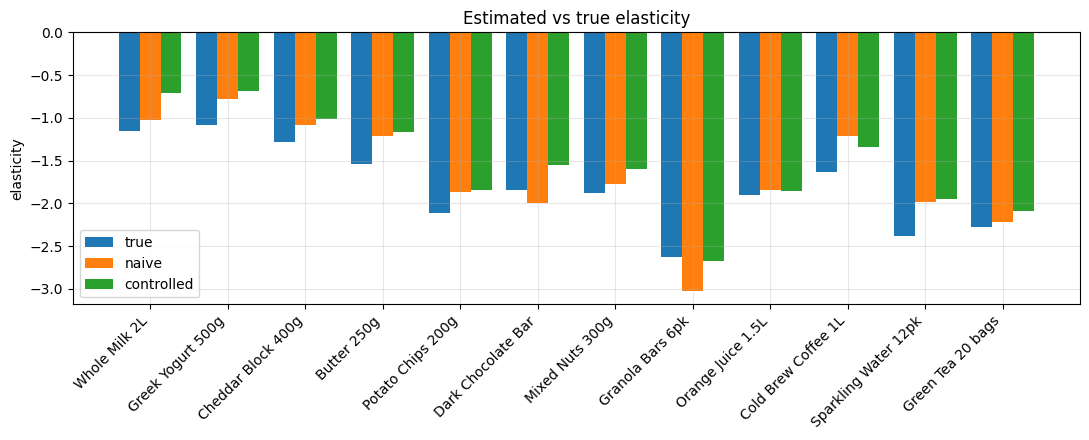

In [6]:
x = np.arange(len(res)); w = .27
plt.figure(figsize=(11, 4.5))
plt.bar(x - w, res.true_elasticity, w, label="true")
plt.bar(x, res.elasticity_naive, w, label="naive")
plt.bar(x + w, res.elasticity_ctrl, w, label="controlled")
plt.xticks(x, res.product_name, rotation=45, ha="right"); plt.ylabel("elasticity"); plt.legend()
plt.title("Estimated vs true elasticity"); plt.tight_layout(); plt.show()

The controlled model is not clearly better, and in this dataset it is a bit worse. My explanation is that the holiday effect works against the endogeneity bias in the naive model. Holiday weeks have both deeper discounts and higher demand, and leaving that out pushes the naive estimate toward *more* elastic, partly cancelling the opposite push from reactive discounting. Adding the holiday control removes that accidental offset. The next sections test whether this holds up beyond one dataset.

## 4. Do the 95% intervals contain the truth?

In [7]:
print(res[["product_name", "true_elasticity", "ci_low_ctrl", "ci_high_ctrl", "covered"]].round(2).to_string(index=False))
print(f"\ncovered: {int(res.covered.sum())} of {len(res)}")

        product_name  true_elasticity  ci_low_ctrl  ci_high_ctrl  covered
       Whole Milk 2L            -1.16        -1.06         -0.36    False
   Greek Yogurt 500g            -1.08        -0.93         -0.45    False
  Cheddar Block 400g            -1.28        -1.33         -0.69     True
         Butter 250g            -1.54        -1.48         -0.84    False
   Potato Chips 200g            -2.11        -2.10         -1.59    False
  Dark Chocolate Bar            -1.85        -1.89         -1.22     True
     Mixed Nuts 300g            -1.87        -1.89         -1.29     True
    Granola Bars 6pk            -2.63        -2.95         -2.39     True
   Orange Juice 1.5L            -1.90        -2.10         -1.61     True
 Cold Brew Coffee 1L            -1.64        -1.64         -1.05     True
Sparkling Water 12pk            -2.38        -2.29         -1.61    False
   Green Tea 20 bags            -2.28        -2.48         -1.70     True

covered: 7 of 12


## 5. Repeating it over 30 simulated datasets

One dataset can be lucky or unlucky, so I regenerate the whole store with 30 different seeds.

abs_bias_naive       0.210
abs_bias_ctrl        0.267
signed_bias_naive    0.106
signed_bias_ctrl     0.262
coverage             0.656

controlled model had the smaller absolute bias in 7 of 30 seeds


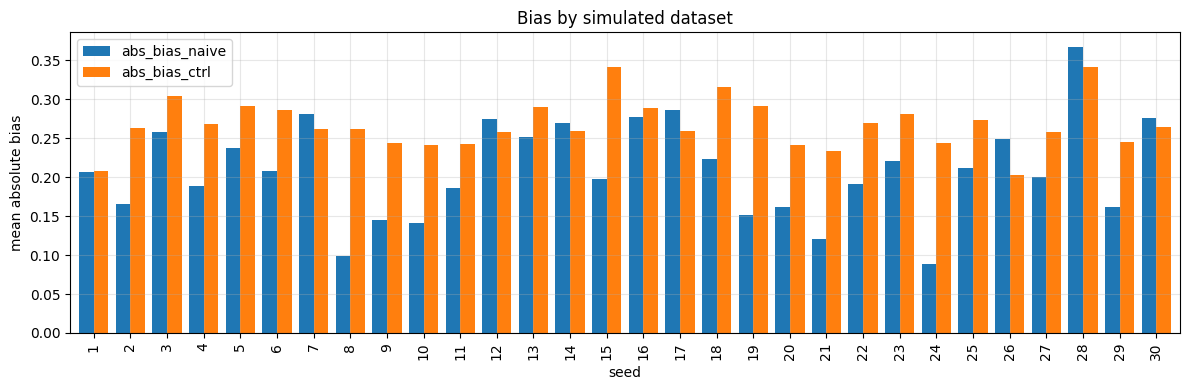

In [8]:
rep = eu.replicate(range(1, 31))
print(rep[["abs_bias_naive", "abs_bias_ctrl", "signed_bias_naive", "signed_bias_ctrl", "coverage"]].mean().round(3).to_string())
print(f"\ncontrolled model had the smaller absolute bias in {int(rep.ctrl_better.sum())} of {len(rep)} seeds")
rep.plot(x="seed", y=["abs_bias_naive", "abs_bias_ctrl"], kind="bar", figsize=(12, 4), width=.8)
plt.ylabel("mean absolute bias"); plt.title("Bias by simulated dataset"); plt.tight_layout(); plt.show()

## 6. Finding profit-maximising prices

I model demand as `q = A * p^e`, with `A` set so the curve passes through each product's average price and units. Profit is `(p - cost) * q`. When `e < -1` the best price is `cost * e / (1 + e)`. When `e >= -1`, profit just keeps rising with price, so there is no sensible answer without a cap.

I cap prices at 1.25x the list price. Any product whose best price lands on the cap is a corner solution, and its predicted gain depends on the cap I picked rather than on the data. I also score every recommendation against the *true* demand curve, which I can only do because the data is simulated.

In [9]:
opt = eu.optimise(df, cat, res, ceiling=1.25)
print(opt[["product_name", "est_elasticity", "price_now", "price_best", "cap", "at_cap", "lift_model_pct", "lift_true_pct"]].round(2).to_string(index=False))
print(f"\nat the cap: {int(opt.at_cap.sum())} of {len(opt)}   interior optimum: {int((~opt.at_cap).sum())}")

        product_name  est_elasticity  price_now  price_best   cap  at_cap  lift_model_pct  lift_true_pct
       Whole Milk 2L           -0.71       2.88        4.00  4.00    True          131.96         100.11
   Greek Yogurt 500g           -0.69       4.33        6.00  6.00    True           78.63          56.96
  Cheddar Block 400g           -1.01       6.77        9.37  9.38    True           84.21          68.82
         Butter 250g           -1.16       4.85        6.75  6.75    True           89.58          67.22
   Potato Chips 200g           -1.84       4.02        5.12  5.62   False            6.06          -0.59
  Dark Chocolate Bar           -1.56       3.50        4.87  4.88    True           12.79           2.37
     Mixed Nuts 300g           -1.59       8.01       11.12 11.12    True           28.33          17.07
    Granola Bars 6pk           -2.67       5.02        5.02  7.12   False            0.00           0.00
   Orange Juice 1.5L           -1.86       4.10        

## 7. How much does the cap matter?

 cap_x_list_price  n_at_cap  n_interior  mean_lift_model_pct  mean_lift_true_pct
             1.00        10           2                15.80               12.49
             1.10        10           2                27.68               20.71
             1.25         8           4                41.13               28.73
             1.40         7           5                51.42               34.13
             1.60         6           6                62.24               38.96
             2.00         5           7                78.09               44.41


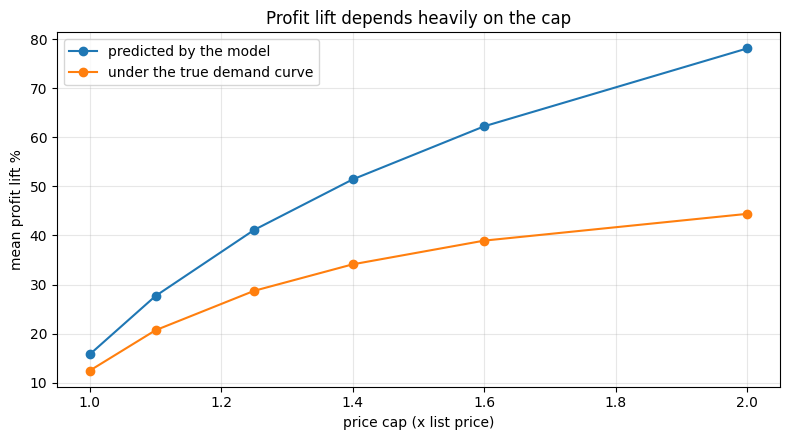

In [10]:
sens = eu.cap_sensitivity(df, cat, res)
print(sens.round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sens.cap_x_list_price, sens.mean_lift_model_pct, marker="o", label="predicted by the model")
ax.plot(sens.cap_x_list_price, sens.mean_lift_true_pct, marker="o", label="under the true demand curve")
ax.set(xlabel="price cap (x list price)", ylabel="mean profit lift %", title="Profit lift depends heavily on the cap"); ax.legend()
plt.tight_layout(); plt.show()

## 8. What I take from this

- **Controls did not fix the bias.** Over 30 datasets the controlled model had lower absolute bias in only 7 of them (mean 0.27 vs 0.21 for the naive model). The estimates are still too close to zero on average, as the endogeneity story predicts.
- **The intervals are overconfident.** Coverage was 7 of 12 here and 66% on average across seeds, well short of 95%.
- **Staples are the hardest case.** The dairy products have true elasticities near -1, and estimates at or above -1 give no interior optimum. All four end up at the cap and show very large predicted gains that I would not trust.
- **Predicted gains overstate real gains.** At the 1.25x cap the model predicts a mean lift of 41% while the true demand curve gives 29%, because elasticity is underestimated.
- **The cap drives the answer.** 8 of 12 products sit at the cap, and the average predicted lift grows from 16% to 78% as the cap goes from 1.0x to 2.0x.

In practice I would use these estimates to rank which products might have pricing room, then confirm with a proper price test (or an instrument such as supplier cost changes) before changing any prices. A constant-elasticity curve is also too simple to give believable optimal prices for low-elasticity staples.